<p class="lead">Nearly every modelling project in the laboratory — a QSAR model of a kinase target, a classifier of screening hits, a predictor of a clinical outcome from gingival-tissue transcriptomes — passes through the same seven decisions, in the same order, and almost every published failure happens in the same two of them. This unit is about the <em>workflow</em>, not the algorithms: trees, forests and networks are taught in the sister artificial-intelligence course. Here you learn how to lay out a supervised project so that the number you finally report is one you can defend in front of a referee — how to frame the question, how to wrap every preprocessing step inside a pipeline fitted on the training fold only, how to compare against baselines that are embarrassingly simple, how to read a learning curve, how to look your own errors in the face, and how to recognise the many faces of <strong>leakage</strong>. We finish by building the same model twice — once naively, once correctly — and measuring, in R² units, how much the naive version lied.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad enseña el flujo de trabajo del aprendizaje supervisado tal como se practica en el laboratorio: cómo se plantea la pregunta (regresión sobre pActivity, clasificación con un umbral o un problema de ordenamiento), cuál es la unidad de predicción cuando un compuesto tiene varias medidas, cómo se construyen <em>pipelines</em> de scikit-learn y <code>ColumnTransformer</code> para que todo preprocesamiento se ajuste solamente con los datos de entrenamiento, por qué siempre se parte de modelos de referencia (la media, el vecino más cercano, un modelo lineal), cómo se leen las curvas de aprendizaje, cómo se analizan los errores compuesto por compuesto, y cuáles son las fuentes de fuga de información (<em>leakage</em>). El experimento central construye el mismo modelo de forma ingenua y de forma correcta y mide el optimismo del primero.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Lay out a supervised project end-to-end: question, target variable, unit of prediction, split, preprocessing, model, evaluation, error analysis.</li>
<li>Decide whether a question is really a regression, a classification at a threshold, or a ranking problem, and state what the unit of prediction is.</li>
<li>Build scikit-learn Pipelines and ColumnTransformers — including a custom transformer — so that every preprocessing step is fitted inside the training fold only.</li>
<li>Always start from baselines (mean/majority, nearest neighbour, a linear model) and report improvement over them rather than a bare score.</li>
<li>Read a learning curve and decide whether the next effort should buy more data or more model capacity.</li>
<li>Perform error analysis: identify which compounds are predicted worst and explain why in chemical terms.</li>
<li>Recognise the five standard leakage sources and quantify the optimism each one produces.</li>
<li>Draft the model card that accompanies a model when it leaves your laptop.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it once linearly, running each code cell as you reach it and reading its output before you move on; then re-run cells while changing one thing at a time — the activity threshold, the feature family, the baseline — and watch the numbers move. Boxes marked <strong>Domain context</strong> define the chemistry and biology vocabulary in plain language; boxes marked <strong>Bridge</strong> point to the unit of this or a sister course that takes the idea further. In Google Colab run <code>!pip install rdkit</code> once before the setup cell; the rest of the stack — NumPy<sup class="c"><a href="#r26">[26]</a></sup>, pandas<sup class="c"><a href="#r30">[30]</a></sup>, matplotlib<sup class="c"><a href="#r11">[11]</a></sup>, scikit-learn<sup class="c"><a href="#r1">[1]</a></sup> and SciPy — is already installed there. This unit assumes Units 4–6 (tidy data, exploratory analysis, curation) and Unit 9 (linear models); Unit 12 takes the single honest number produced here and asks how much it should be trusted.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit
from pathlib import Path
import urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, rdkit
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| rdkit", rdkit.__version__)

numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | rdkit 2026.03.4


## 1. The seven decisions of a supervised project

A supervised project is a chain of seven decisions, of which only the fifth is about an algorithm — the least consequential of them.

1. **The question.** What will somebody *do* with the prediction — buy a compound, synthesise an analogue, send a patient for a biopsy? This fixes everything downstream, including which errors are expensive.
2. **The target.** Which measured quantity encodes the answer, on which scale, with which measurement error, and which records are usable at all.
3. **The unit of prediction.** One row = one *what*? One measurement, compound, patient, tissue site? Rows must be the things you will be asked to predict.
4. **The split.** Which data are hidden from the model, and whether hiding them that way mimics how the model will be used. Unit 12 is entirely about this decision.
5. **The preprocessing and the model.** Scaling, imputation, encoding, featurisation, then an estimator — all inside one object fitted on a training fold and applied, never refitted, to a test fold.
6. **The evaluation.** A metric matching the question, computed on data the chain never saw, reported with an uncertainty and against a baseline.
7. **The error analysis.** Which rows are wrong, whether they are wrong for a reason, and what that implies about the applicability of the model.

Most published disasters in machine learning for science happen in decisions 3, 4 and 5 — not in the choice of algorithm but in the mechanics of how the preprocessing was fitted. The survey of Kapoor and Narayanan found leakage-induced over-optimism in hundreds of papers across seventeen fields<sup class="c"><a href="#r3">[3]</a></sup>, and reviews of machine learning in genomics<sup class="c"><a href="#r6">[6]</a></sup> and chemistry<sup class="c"><a href="#r7">[7]</a></sup> make the same diagnosis. This unit makes those mistakes mechanically impossible in your own code.

<div class="box bridge"><h4>Domain context — ROCK1, IC50 and the pActivity scale</h4>
<p><strong>ROCK1</strong> (Rho-associated protein kinase 1) is an enzyme — a <em>kinase</em>, that is, a protein that attaches a phosphate group to other proteins and so switches them on or off. It sits downstream of the signalling protein RhoA and controls how a cell contracts its internal skeleton; drugs that block it (fasudil, ripasudil, belumosudil) are studied for glaucoma, fibrosis and cardiovascular disease, and it is one of this laboratory's own targets. A chemist measures how well a candidate blocks it and reports a concentration: the <strong>IC50</strong> halves the enzyme's activity, while <strong>Ki</strong>/<strong>Kd</strong> are related binding constants. A <em>smaller</em> concentration means a <em>better</em> compound, and the values span nine orders of magnitude, so the field works with <strong>pActivity</strong> = −log<sub>10</sub>(concentration in molar). pActivity 9 is an excellent inhibitor (1 nM), pActivity 5 is a weak one (10 µM), and one unit of pActivity is a tenfold change in potency. Because different laboratories and assay formats disagree by roughly half a log unit even for the same compound<sup class="c"><a href="#r13">[13]</a></sup><sup class="c"><a href="#r14">[14]</a></sup>, a model that predicts pActivity to ±0.5 is already at the level of the experiment itself. Our data are a frozen snapshot of the public database <strong>ChEMBL</strong><sup class="c"><a href="#r9">[9]</a></sup>, curated in Unit 6.</p></div>

The cell below loads the curated table and shows the columns that matter for this unit. Everything in Units 11–14 runs on this one file.

In [2]:
# The curated compound-level table: one row per standardised structure (see data/README_rock1.md).
df = load_data("rock1_chembl_curated.csv")
print("curated table:", df.shape[0], "compounds x", df.shape[1], "columns")
print("censored (all measurements are '>' or '<'):", int(df['censored'].sum()),
      "| with at least one exact value:", int((~df['censored']).sum()))
cols = ["pActivity", "n_measurements", "pActivity_range", "MolWt", "MolLogP", "TPSA", "QED"]
df.loc[~df["censored"], cols].describe().round(2)

curated table: 4280 compounds x 33 columns
censored (all measurements are '>' or '<'): 1516 | with at least one exact value: 2764


,pActivity,n_measurements,pActivity_range,MolWt,MolLogP,TPSA,QED
count,2764.00,2764.00,2764.00,2764.00,2764.00,2764.00,2764.00
mean,6.51,1.22,0.05,381.59,3.52,86.41,0.57
std,1.11,1.00,0.26,80.25,1.14,26.02,0.17
min,3.57,1.00,0.00,133.15,-1.27,12.89,0.04
25%,5.73,1.00,0.00,332.41,2.80,68.96,0.44
50%,6.44,1.00,0.00,373.65,3.57,83.72,0.58
75%,7.30,1.00,0.00,431.54,4.24,100.87,0.72
max,9.82,24.00,3.30,915.85,7.54,382.54,0.94


<p class="caption"><b>Table (Section 1).</b> Summary of the modelling subset. The 2,764 compounds with at least one exact measurement have a mean pActivity of about 6.5 and a standard deviation of about 1.1 log units, spanning 3.6 to 9.8 — four orders of magnitude of potency. Molecular weight averages about 382 g/mol and MolLogP about 3.5: drug-sized kinase inhibitors, not a random library. That standard deviation of 1.11 is the number every model here must beat, since predicting the mean already achieves it.</p>

### 1.1 Decision 2 — the target, and who is allowed into the table

The target is `pActivity`. Two groups of records require a decision before any modelling.

**Censored measurements.** When an assay reports "IC50 > 10 µM" the true value is unknown; all we know is that it lies above a bound. The curated table keeps those 1,516 compounds (`censored = True`) rather than deleting them silently, because they are exactly the inactive compounds and discarding them makes a dataset look easier and more potent than reality. They cannot enter an ordinary regression as if the bound were the value, so this unit models the 2,764 compounds with at least one exact measurement and *states* that restriction; Unit 17 handles censoring properly.

**Replicate spread.** A compound measured four times in four laboratories has four answers. The table stores the median of the exact measurements plus the spread, flagging 60 compounds that disagree by more than one log unit. That spread is the experimental noise floor: no model can be more accurate than the data are reproducible<sup class="c"><a href="#r13">[13]</a></sup>.

target sd = 1.109 | median replicate range = 0.0 | compounds disagreeing by >1 log unit: 55


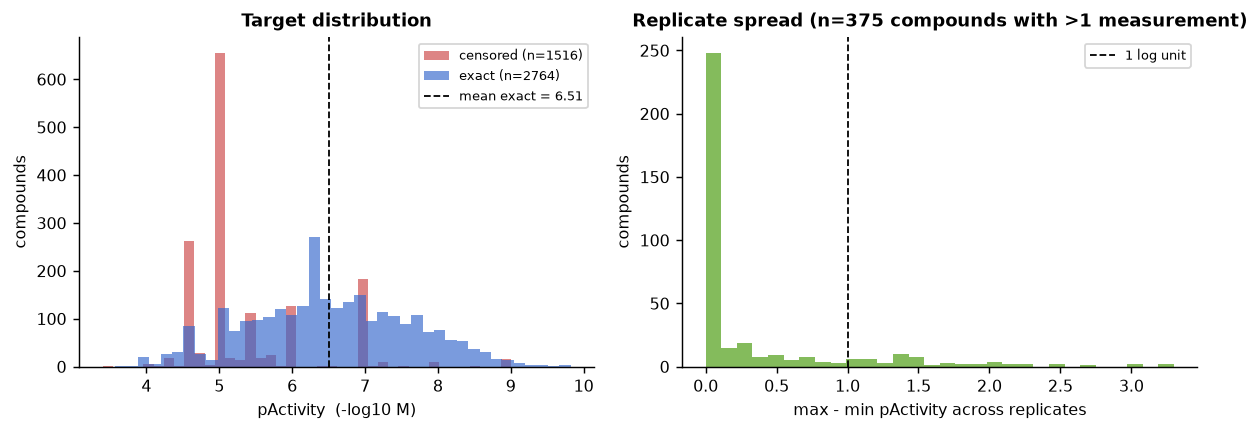

In [3]:
# The target distribution, exact vs censored, and the noise floor implied by replicates.
reg = df.loc[~df["censored"]].reset_index(drop=True)      # modelling subset: exact values only
y = reg["pActivity"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.4))
axes[0].hist(df.loc[df["censored"], "pActivity"], bins=40, alpha=0.65, label=f"censored (n={int(df['censored'].sum())})", color="#c44")
axes[0].hist(y, bins=40, alpha=0.65, label=f"exact (n={len(y)})", color="#36c")
axes[0].axvline(y.mean(), color="k", ls="--", lw=1, label=f"mean exact = {y.mean():.2f}")
axes[0].set_xlabel("pActivity  (-log10 M)"); axes[0].set_ylabel("compounds")
axes[0].set_title("Target distribution"); axes[0].legend(fontsize=7)
rep = reg.loc[reg["n_measurements"] > 1, "pActivity_range"]
axes[1].hist(rep, bins=30, color="#6a3", alpha=0.8)
axes[1].axvline(1.0, color="k", ls="--", lw=1, label="1 log unit")
axes[1].set_xlabel("max - min pActivity across replicates"); axes[1].set_ylabel("compounds")
axes[1].set_title(f"Replicate spread (n={len(rep)} compounds with >1 measurement)"); axes[1].legend(fontsize=7)
fig.tight_layout()
print("target sd =", round(float(y.std(ddof=1)), 3),
      "| median replicate range =", round(float(rep.median()), 3),
      "| compounds disagreeing by >1 log unit:", int((rep > 1).sum()))

<p class="caption"><b>Figure 1.</b> Left: the two populations of the curated table. The exact measurements (blue, 2,764 compounds) are roughly bell-shaped around pActivity 6.5, while the censored records (red, 1,516 compounds) pile up at low potency — compounds somebody tested and found inactive, reported as "greater than" a screening concentration. Right: for the compounds measured more than once, the spread between the largest and smallest replicate. The median spread is zero — most compounds were measured once or twice in agreement — but the tail reaches beyond one log unit for 55 compounds of the modelling subset, and that tail is the empirical noise floor of the target.</p>

### 1.2 Decision 3 — the unit of prediction

The raw ChEMBL download has 5,089 rows, one per *measurement*. The curated table has 4,280 rows, one per *compound*. Which should be the unit of prediction?

If a row were a measurement, the same molecule could appear in both training and test set — ten times in training, twice in test — and the test score would partly measure the model's ability to remember a structure it has already seen. That is the simplest form of leakage, and it is why Unit 6 aggregated measurements to one row per standardised parent structure. The unit of prediction here is **one compound**, because the question — "should we buy or synthesise this molecule?" — is asked once per molecule.

The analogous decision in the clinical dataset of Unit 21 is sharper: the periodontitis series has two tissue sites per patient, so a row is a *site* but the independent unit is a *patient*. Whenever rows are nested inside a larger unit (measurements in compounds, sites in patients, frames in a trajectory) the unit of prediction is the outer one, and the split must respect it — the `GroupKFold` of Unit 12.

<div class="box warn"><h4>Common misconception</h4>
<p>"More rows is more data, so I should model measurements, not compounds." More rows that are copies of each other is not more information; it is the same information with a louder voice. It inflates the apparent sample size, breaks the independence assumption of every confidence interval you will later compute, and — if the duplicates straddle the split — inflates the test score as well.</p></div>

### 1.3 Decision 1 revisited — regression, classification, or ranking?

The same data support three different questions, and the choice is made by the use, not by the data.

- **Regression on pActivity.** Predict the number. Appropriate when the downstream decision uses the magnitude: "is this analogue likely to reach single-digit nanomolar?" Metrics: RMSE, MAE, R², Spearman ρ.
- **Classification at a threshold.** Predict active/inactive, where "active" means pActivity above some cut-off. Appropriate when the decision is binary and the threshold is a real decision boundary (a screening cut-off, a potency gate for a project). Metrics: ROC-AUC, precision/recall, MCC. The cost: a compound at 6.99 and one at 7.01 become different classes, while 7.01 and 9.8 become the same class.
- **Ranking.** Predict an order, and care only about the top of it. This is what a virtual screening campaign actually needs: the top 1% of a million-compound library is what gets bought. Metrics: enrichment factor, BEDROC, Spearman ρ on the top slice — Unit 19.

The threshold is a modelling decision with consequences, so look at what it does to the class balance before choosing it.

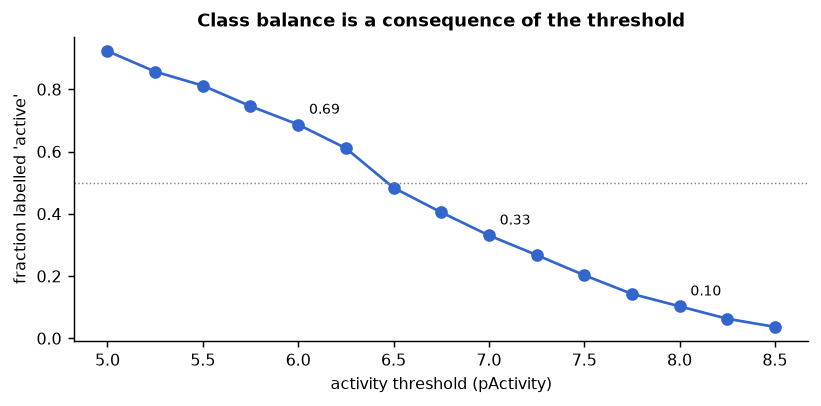

,threshold,n_active,n_inactive,active_fraction
4,6.0,1898,866,0.687
6,6.5,1339,1425,0.484
8,7.0,914,1850,0.331
10,7.5,561,2203,0.203
12,8.0,286,2478,0.103


In [4]:
# What a threshold does: class balance and the fraction of 'actives' as the cut-off moves.
ths = np.round(np.arange(5.0, 8.51, 0.25), 2)
bal = pd.DataFrame({"threshold": ths,
                    "n_active": [(y >= t).sum() for t in ths],
                    "n_inactive": [(y < t).sum() for t in ths]})
bal["active_fraction"] = (bal["n_active"] / len(y)).round(3)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(bal["threshold"], bal["active_fraction"], "o-", color="#36c")
for t in (6.0, 7.0, 8.0):
    f = float(bal.loc[bal["threshold"] == t, "active_fraction"].iloc[0])
    ax.annotate(f"{f:.2f}", (t, f), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.axhline(0.5, color="grey", ls=":", lw=0.8)
ax.set_xlabel("activity threshold (pActivity)"); ax.set_ylabel("fraction labelled 'active'")
ax.set_title("Class balance is a consequence of the threshold")
fig.tight_layout()
bal.loc[bal["threshold"].isin([6.0, 6.5, 7.0, 7.5, 8.0])]

<p class="caption"><b>Figure 2 and table.</b> Moving the activity threshold from 6.0 to 8.0 turns a 69%-active dataset into a 10%-active one: at pActivity ≥ 6.0 there are 1,898 actives against 866 inactives, at ≥ 7.0 the split is 914 against 1,850, and at ≥ 8.0 only about 290 remain active. Every classification metric in Unit 12 depends on this fraction — ROC-AUC least, precision and PR-AUC most — so the threshold must be reported with the metric, and classifiers trained at different thresholds are not comparable. For the classification examples in this unit we use pActivity ≥ 7.0, that is 100 nM, which is both a round number and a plausible project-relevant potency gate.</p>

<div class="exercise"><h4>Exercise 1</h4>
<p>Re-run the cell above with thresholds between 4 and 10 in steps of 0.1 and find the threshold that balances the classes exactly. Then answer in one sentence why "the threshold that balances the classes" is almost never the right threshold scientifically, and what information you would need from a project chemist to choose it properly.</p></div>

## 2. The two feature families

A molecule is a graph, and no algorithm consumes graphs directly; Unit 5 of the cheminformatics course turns structures into vectors. Two families of vector dominate practice, and this block uses both because they have completely different statistics.

- **RDKit descriptors** — here eleven numbers per molecule (molecular weight, calculated lipophilicity MolLogP, topological polar surface area TPSA, counts of hydrogen-bond donors and acceptors, rotatable bonds, aromatic and total rings, heavy atoms, the fraction of sp³ carbons, and the composite drug-likeness score QED<sup class="c"><a href="#r25">[25]</a></sup>). They are dense, continuous, strongly correlated with one another and with molecular size, and each one is interpretable<sup class="c"><a href="#r27">[27]</a></sup>.
- **Morgan fingerprints** (also called ECFP) — a 2,048-bit vector per molecule in which each bit records the presence of a circular atom environment of radius ≤ 2<sup class="c"><a href="#r10">[10]</a></sup>. They are sparse (about 2.5% of bits set per molecule), binary, high-dimensional, and individually meaningless but collectively a faithful record of substructure.

The two families answer different questions — "what are this molecule's bulk properties?" versus "which pieces is it made of?" — and they behave differently in every experiment that follows.

In [5]:
# Build the two feature matrices once; everything downstream reuses them.
DESC = ["MolWt", "MolLogP", "TPSA", "HBD", "HBA", "RotB",
        "AromaticRings", "RingCount", "HeavyAtoms", "FractionCSP3", "QED"]
X_desc = reg[DESC].to_numpy(dtype=float)
mols = [Chem.MolFromSmiles(s) for s in reg["std_smiles"]]
assert all(m is not None for m in mols), "every standardised SMILES must parse"
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X_fp = np.array([mfpgen.GetFingerprintAsNumPy(m) for m in mols], dtype=np.float32)
fps = [mfpgen.GetFingerprint(m) for m in mols]            # RDKit objects, for Tanimoto similarity later
print("descriptors:", X_desc.shape, "| fingerprints:", X_fp.shape)
print("bits set per molecule: mean %.1f (%.2f%% of 2048) | bits never set in the whole set: %d"
      % (X_fp.sum(1).mean(), 100 * X_fp.mean(), int((X_fp.sum(0) == 0).sum())))
print("columns (bits) present in at least 1%% of compounds: %d"
      % int((X_fp.mean(0) >= 0.01).sum()))

descriptors: (2764, 11) | fingerprints: (2764, 2048)
bits set per molecule: mean 52.3 (2.55% of 2048) | bits never set in the whole set: 45
columns (bits) present in at least 1% of compounds: 719


The two matrices have the same number of rows and wildly different shapes: 11 dense columns against 2,048 sparse ones. Only 45 bits are never set here, but the distribution is extremely uneven: about 719 bits occur in at least 1% of compounds and the rest are too rare to be useful. Unit 13 returns to this asymmetry in detail. The figure below shows both faces at once.

largest absolute descriptor correlation: 0.98 between MolWt and HeavyAtoms


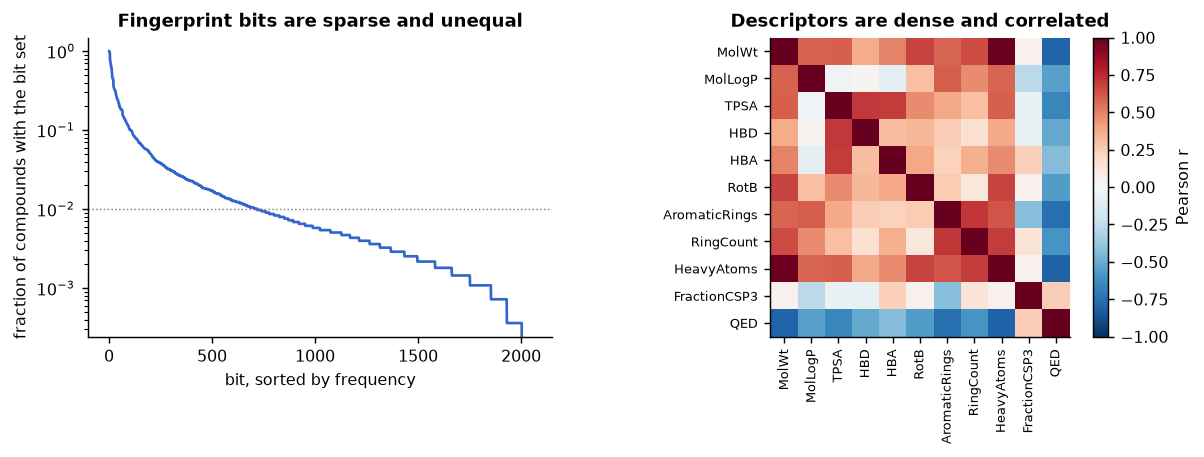

In [6]:
# Left: how often each fingerprint bit is set. Right: the descriptor correlation matrix.
freq = np.sort(X_fp.mean(0))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))
axes[0].plot(np.arange(1, 2049), freq, color="#36c")
axes[0].set_yscale("log"); axes[0].set_xlabel("bit, sorted by frequency")
axes[0].set_ylabel("fraction of compounds with the bit set")
axes[0].set_title("Fingerprint bits are sparse and unequal")
axes[0].axhline(0.01, color="grey", ls=":", lw=0.8)
C = np.corrcoef(X_desc, rowvar=False)
im = axes[1].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(DESC))); axes[1].set_xticklabels(DESC, rotation=90, fontsize=7)
axes[1].set_yticks(range(len(DESC))); axes[1].set_yticklabels(DESC, fontsize=7)
axes[1].set_title("Descriptors are dense and correlated")
fig.colorbar(im, ax=axes[1], fraction=0.046, label="Pearson r")
fig.tight_layout()
iu = np.triu_indices(len(DESC), 1)
print("largest absolute descriptor correlation: %.2f between %s and %s"
      % (np.abs(C[iu]).max(), DESC[iu[0][np.abs(C[iu]).argmax()]], DESC[iu[1][np.abs(C[iu]).argmax()]]))

<p class="caption"><b>Figure 3.</b> The two feature families seen through their statistics. Left: fingerprint bit frequencies on a logarithmic scale, sorted — a handful of bits occur in most molecules, a few hundred in more than 1% of them (dotted line), and the rest are rare or absent; this long tail is what makes sparse binary data different from ordinary tabular data. Right: the correlation matrix of the eleven descriptors, whose deep red block shows that molecular weight, heavy-atom count and hydrogen-bond acceptors measure nearly the same thing (largest absolute correlation about 0.98, printed below). Eleven descriptors are not eleven independent pieces of information — which matters for linear models (Unit 9) and for feature selection (Unit 13).</p>

## 3. Decisions 4 and 5 — the split and the pipeline

### 3.1 The split, in one line and with one caveat

For the rest of this unit we hold out 20% of the compounds at random, fit everything on the remaining 80%, and touch the held-out fifth exactly twice: once in the error analysis of Section 7 and once in the model card of Section 9. Within the training 80% we use five-fold cross-validation for every comparison.

A random split is the *wrong* split for molecules, and Unit 12 shows by how much. We use it here because this unit is about pipeline mechanics and the random split is the baseline against which the scaffold split is read; everything below is split-agnostic, and swapping `KFold` for `GroupKFold` changes one line.

In [7]:
# One held-out test set (20%) and one inner cross-validation scheme, used by every comparison below.
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict
idx = np.arange(len(y))
idx_tr, idx_te = train_test_split(idx, test_size=0.20, random_state=0)
cv5 = KFold(n_splits=5, shuffle=True, random_state=0)
print("train:", len(idx_tr), "compounds | test:", len(idx_te), "compounds")
seen = set(reg["scaffold_smiles"].to_numpy()[idx_tr])
unseen_scaffold = ~np.isin(reg["scaffold_smiles"].to_numpy()[idx_te], list(seen))
print("test compounds whose Bemis-Murcko scaffold never appears in training:",
      int(unseen_scaffold.sum()), f"({100*unseen_scaffold.mean():.0f}%)")
print("distinct scaffolds overall:", reg['scaffold_smiles'].nunique(),
      "| singletons:", int((reg['scaffold_smiles'].value_counts() == 1).sum()))

train: 2211 compounds | test: 553 compounds
test compounds whose Bemis-Murcko scaffold never appears in training: 212 (38%)
distinct scaffolds overall: 1218 | singletons: 858


The output records something we will need twice. A random split leaves about 38% of the test compounds with a scaffold — the ring framework that defines a chemical series<sup class="c"><a href="#r12">[12]</a></sup> — that the model has never seen, and the other 62% with a scaffold it has seen, often together with close analogues. Those two populations are not equally difficult, and reporting their average as one number hides the difference. Section 7 measures the gap.

### 3.2 Why a Pipeline, and what exactly goes wrong without one

Every preprocessing step that *learns something from the data* — a mean and a standard deviation for scaling, a median for imputation, a set of categories for one-hot encoding, a list of selected features, a PCA rotation — is a model with parameters, and those parameters must be estimated from the training fold alone. If you standardise the whole dataset before splitting, the test rows have contributed their mean to the transformation, and the evaluation is no longer blind. The effect is usually small for a simple scaler and large for anything supervised (feature selection, target encoding); Section 8 measures both.

A scikit-learn `Pipeline`<sup class="c"><a href="#r1">[1]</a></sup> is a single estimator that chains transformers and ends with a predictor. Calling `fit` fits every step in order on the training data; calling `predict` applies the *already fitted* transformers. Passing the pipeline to `cross_validate` therefore refits the whole chain inside every fold, which is exactly the behaviour you want and almost impossible to achieve by hand without a mistake.

In [8]:
# The minimal correct object: scale, then fit a ridge regression — as ONE estimator.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
pipe_desc = Pipeline([("scale", StandardScaler()),
                      ("model", Ridge(alpha=1.0, random_state=None))])
pipe_desc.fit(X_desc[idx_tr], y[idx_tr])
mu = pipe_desc.named_steps["scale"].mean_
print("the scaler learned its mean from", len(idx_tr), "training compounds only;")
print("  mean MolWt used by the transform : %.2f" % mu[0])
print("  mean MolWt of the full dataset   : %.2f  (never seen by this pipeline)" % X_desc[:, 0].mean())
print("pipeline steps:", [n for n, _ in pipe_desc.steps])
print("train R2 = %.3f | test R2 = %.3f"
      % (pipe_desc.score(X_desc[idx_tr], y[idx_tr]), pipe_desc.score(X_desc[idx_te], y[idx_te])))

the scaler learned its mean from 2211 training compounds only;
  mean MolWt used by the transform : 381.57
  mean MolWt of the full dataset   : 381.59  (never seen by this pipeline)
pipeline steps: ['scale', 'model']
train R2 = 0.128 | test R2 = 0.117


The two printed means differ only in the fifth significant digit (381.57 against 381.59): scaling is unsupervised and 2,211 compounds estimate a mean well. Use the pipeline anyway, because the *discipline* generalises — the object that protects you from a leaky scaler protects you from a leaky feature selector, where the optimism is not trivial at all.

### 3.3 ColumnTransformer: tables whose columns are not all the same kind

Real tables mix numeric columns, categorical columns and missing values. `ColumnTransformer` applies a different sub-pipeline to each group of columns and glues the results together. The example below builds a mixed table from the ROCK1 data: the eleven numeric descriptors, the mostly-missing clinical-phase column (`max_phase`, present for only 47 of the 2,764 modelled compounds), and a categorical column recording which assay type dominates the compound's measurements — IC50, Ki or Kd, a genuine source of systematic offset between records<sup class="c"><a href="#r13">[13]</a></sup>.

In [9]:
# A mixed-type table: numeric descriptors (imputed + scaled), a sparse numeric column, one categorical.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
tab = reg[DESC + ["max_phase"]].copy()
tab["assay_family"] = np.where(reg["n_IC50"] >= np.maximum(reg["n_Ki"], reg["n_Kd"]), "IC50",
                      np.where(reg["n_Ki"] >= reg["n_Kd"], "Ki", "Kd"))
prep = ColumnTransformer(
    [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
      DESC + ["max_phase"]),
     ("cat", OneHotEncoder(handle_unknown="ignore"), ["assay_family"])])
pipe_mixed = Pipeline([("prep", prep), ("model", Ridge(alpha=1.0))])
s = cross_validate(pipe_mixed, tab, y, cv=cv5, scoring=["r2", "neg_root_mean_squared_error"])
print("assay_family counts:", tab['assay_family'].value_counts().to_dict())
print("max_phase missing in", int(tab['max_phase'].isna().sum()), "of", len(tab), "rows -> imputed with the TRAINING median")
print("feature names after preprocessing:", list(prep.fit(tab, y).get_feature_names_out()[-4:]))
print("5-fold CV: R2 = %.3f | RMSE = %.3f"
      % (s["test_r2"].mean(), -s["test_neg_root_mean_squared_error"].mean()))

assay_family counts: {'IC50': 1902, 'Ki': 828, 'Kd': 34}
max_phase missing in 2717 of 2764 rows -> imputed with the TRAINING median
feature names after preprocessing: ['num__max_phase', 'cat__assay_family_IC50', 'cat__assay_family_Kd', 'cat__assay_family_Ki']
5-fold CV: R2 = 0.118 | RMSE = 1.038


The mixed table reaches an R² of about 0.12 — barely better than predicting the mean — which is the honest verdict on eleven bulk descriptors plus two administrative columns as a model of kinase potency. The point of the cell is not the score but the mechanics: the median that fills the missing `max_phase` values is computed inside each training fold, the one-hot encoder is told to ignore categories it has never seen (`handle_unknown="ignore"`), and `get_feature_names_out` lets you trace every column of the final matrix back to its origin — the single most useful debugging habit with composite preprocessing.

### 3.4 A custom transformer: featurisation inside the pipeline

Descriptors and fingerprints are themselves preprocessing. For a *deterministic, row-wise* featurisation such as a Morgan fingerprint, computing it once before the split is safe — the fingerprint of a molecule does not depend on any other molecule. The habit becomes dangerous the moment the featurisation learns from the set as a whole: a bit filter ("keep bits present in at least 1% of compounds"), a scaler, a PCA, a learned embedding. Those must live inside the pipeline.

Writing a transformer is three methods: `fit` (learn, return `self`), `transform` (apply), and inheritance from `BaseEstimator` and `TransformerMixin` so that cloning and `get_params` work. The transformer below takes a column of SMILES strings and returns the fingerprint matrix, dropping bits that are too rare *in the training fold*.

In [10]:
# A custom transformer: SMILES -> Morgan fingerprint matrix, with a training-fold-only rare-bit filter.
from sklearn.base import BaseEstimator, TransformerMixin
class MorganFingerprint(BaseEstimator, TransformerMixin):
    '''Featurise a 1-column array/Series of SMILES into Morgan bits (radius 2).'''
    def __init__(self, radius=2, n_bits=2048, min_freq=0.0):
        self.radius, self.n_bits, self.min_freq = radius, n_bits, min_freq
    def _matrix(self, X):
        smis = np.asarray(X).ravel()
        gen = rdFingerprintGenerator.GetMorganGenerator(radius=self.radius, fpSize=self.n_bits)
        return np.array([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smis], dtype=np.float32)
    def fit(self, X, y=None):
        M = self._matrix(X)
        self.keep_ = np.where(M.mean(0) >= self.min_freq)[0]   # learned from the training fold only
        return self
    def transform(self, X):
        return self._matrix(X)[:, self.keep_]

pipe_fp = Pipeline([("fp", MorganFingerprint(min_freq=0.01)), ("model", Ridge(alpha=1.0))])
s = cross_validate(pipe_fp, reg[["std_smiles"]], y, cv=cv5, scoring=["r2", "neg_root_mean_squared_error"])
pipe_fp.fit(reg[["std_smiles"]].iloc[idx_tr], y[idx_tr])
print("bits kept (>=1% frequency in the training fold):", len(pipe_fp.named_steps['fp'].keep_), "of 2048")
print("5-fold CV from raw SMILES: R2 = %.3f | RMSE = %.3f"
      % (s["test_r2"].mean(), -s["test_neg_root_mean_squared_error"].mean()))

bits kept (>=1% frequency in the training fold): 716 of 2048
5-fold CV from raw SMILES: R2 = 0.428 | RMSE = 0.836


This pipeline takes *chemistry* as input — a column of SMILES strings — and returns potency predictions, with the rare-bit filter refitted in every fold. About 716 of the 2,048 bits survive the 1% filter, and the cross-validated R² is near 0.43 (RMSE about 0.84), roughly four times the descriptor model's 0.11. A pipeline of this shape is what should be pickled and shipped at the end of a project: it is the only object that reproduces the full transformation from raw data to prediction.

<div class="box key"><h4>Key idea</h4>
<p>The pipeline is not a convenience; it is the formal statement of what your model <em>is</em>. If the artefact is "a ridge regression plus a scaler from cell 12 plus a bit filter from cell 7", nobody — including you in six months — can reproduce the prediction. If it is one <code>Pipeline</code>, then <code>fit</code>, <code>cross_validate</code> and <code>GridSearchCV</code> all do the right thing automatically.</p></div>

## 4. Baselines, and the only honest way to report a score

An R² of 0.33 means nothing by itself. Compared to what? Three baselines belong in every supervised project, and they cost seconds:

- **The constant baseline.** Predict the training mean for every compound (`DummyRegressor`), or the majority class for every patient. Its RMSE is the standard deviation of the target; its R² is 0 by construction. Any model that does not beat it is not a model.
- **The nearest-neighbour baseline.** Predict the activity of the single most similar training compound. In chemistry this is a strong baseline and a meaningful one: it is the quantitative form of "look up the closest analogue in the series", which is what a medicinal chemist does without any model at all<sup class="c"><a href="#r22">[22]</a></sup>.
- **The linear baseline.** A ridge regression<sup class="c"><a href="#r21">[21]</a></sup> on the same features. If a random forest cannot beat a regularised linear model, the extra complexity is not earning its keep.

The table below computes all three on both feature families, plus a random forest<sup class="c"><a href="#r19">[19]</a></sup><sup class="c"><a href="#r20">[20]</a></sup> on each, inside the same five-fold cross-validation of the training set. The nearest-neighbour model on fingerprints uses the Jaccard (Tanimoto) metric, the standard similarity measure for binary substructure vectors.

In [11]:
# Baselines and two real models, all under the same 5-fold CV of the training set. (~40 s)
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
Xtr_d, Xtr_f, ytr = X_desc[idx_tr], X_fp[idx_tr], y[idx_tr]
cands = [("mean (DummyRegressor)",   DummyRegressor(strategy="mean"), Xtr_d),
         ("1-NN, descriptors",       Pipeline([("sc", StandardScaler()), ("m", KNeighborsRegressor(1))]), Xtr_d),
         ("ridge, descriptors",      Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]), Xtr_d),
         ("random forest, descriptors", RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1), Xtr_d),
         ("1-NN, fingerprints (Tanimoto)", KNeighborsRegressor(1, metric="jaccard"), Xtr_f),
         ("ridge, fingerprints",     Ridge(alpha=1.0), Xtr_f),
         ("random forest, fingerprints", RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1), Xtr_f)]
rows = []
for name, est, X in cands:
    s = cross_validate(est, X, ytr, cv=cv5, scoring=["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"])
    rows.append({"model": name, "RMSE": -s["test_neg_root_mean_squared_error"].mean(),
                 "RMSE_sd": s["test_neg_root_mean_squared_error"].std(),
                 "MAE": -s["test_neg_mean_absolute_error"].mean(), "R2": s["test_r2"].mean(),
                 "fit_s": s["fit_time"].mean()})
base = pd.DataFrame(rows).set_index("model").round(3)
base["RMSE_vs_mean_%"] = (100 * (1 - base["RMSE"] / base.loc["mean (DummyRegressor)", "RMSE"])).round(1)
base

/usr/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2474: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/usr/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2474: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/usr/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2474: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/usr/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2474: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/usr/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2474: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


,RMSE,RMSE_sd,MAE,R2,fit_s,RMSE_vs_mean_%
model,,,,,,
mean (DummyRegressor),1.107,0.029,0.900,-0.004,0.000,0.0
"1-NN, descriptors",1.133,0.064,0.818,-0.056,0.001,-2.3
"ridge, descriptors",1.041,0.035,0.835,0.112,0.001,6.0
"random forest, descriptors",0.918,0.043,0.709,0.308,0.210,17.1
"1-NN, fingerprints (Tanimoto)",0.958,0.033,0.681,0.248,0.003,13.5
"ridge, fingerprints",0.915,0.025,0.696,0.312,0.044,17.3
"random forest, fingerprints",0.759,0.022,0.565,0.528,3.133,31.4


<p class="caption"><b>Table (Section 4).</b> Five-fold cross-validated performance on the training compounds. The constant baseline has RMSE 1.11 (the target's standard deviation) and R² ≈ 0. Reading down the table: a 1-nearest-neighbour model on descriptors is <em>worse</em> than the mean (RMSE ≈ 1.13, R² ≈ −0.06) — bulk properties do not identify a useful analogue; ridge on descriptors improves little (R² ≈ 0.11); the random forest on descriptors reaches R² ≈ 0.31; and on fingerprints, 1-NN by Tanimoto similarity alone achieves R² ≈ 0.25, ridge ≈ 0.31 and the random forest ≈ 0.53, with RMSE about 0.76, a 31% reduction over the constant baseline. The last column is the number to report in a paper: "the model reduces RMSE by 31% relative to predicting the mean", not a bare R². Note also the cost column — the forest on 2,048 bits takes about four seconds per fit against milliseconds for ridge, which is the exchange rate between accuracy and compute you will negotiate again in Unit 14.</p>

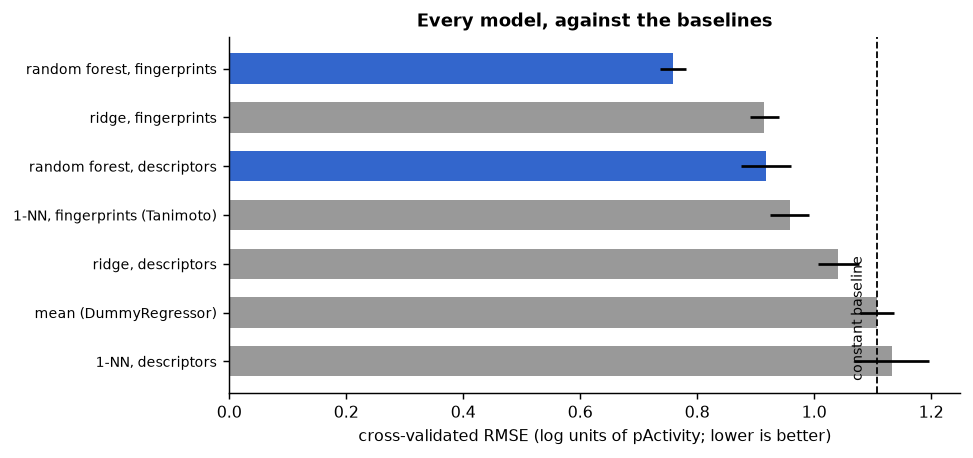

In [12]:
# The same table as a figure, with the baselines marked.
fig, ax = plt.subplots(figsize=(7.6, 3.6))
order = base.sort_values("RMSE", ascending=False)
colors = ["#999" if ("Dummy" in m or "1-NN" in m or "ridge" in m) else "#36c" for m in order.index]
ax.barh(range(len(order)), order["RMSE"], xerr=order["RMSE_sd"], color=colors, height=0.62)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order.index, fontsize=8)
ax.axvline(base.loc["mean (DummyRegressor)", "RMSE"], color="k", ls="--", lw=1)
ax.text(base.loc["mean (DummyRegressor)", "RMSE"] - 0.02, -0.4, "constant baseline",
        ha="right", fontsize=7.5, rotation=90, va="bottom")
ax.set_xlabel("cross-validated RMSE (log units of pActivity; lower is better)")
ax.set_xlim(0, 1.25); ax.set_title("Every model, against the baselines")
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> The baseline comparison as a figure; grey bars are baselines, blue bars are the two random forests, error bars are the standard deviation across the five folds. Two lessons are visible at a glance. First, the only large jump comes from changing the <em>representation</em> (descriptors → fingerprints) rather than the algorithm; the choice of features dominates the choice of model, which is why Unit 13 exists. Second, the fold-to-fold standard deviation (about 0.03–0.05 RMSE units) is the yardstick for judging whether two bars differ: differences smaller than that are noise, and Unit 12 makes that intuition into a test.</p>

### 4.1 The sanity check that costs one line

Before believing any pipeline, shuffle the labels and re-run it. With the correspondence between molecules and activities destroyed, an honest evaluation must return R² ≈ 0 (in practice slightly negative) and RMSE ≈ the target standard deviation. If it does not, something in the chain is reading the target.

In [13]:
# Sanity check: destroy the structure-activity relationship and verify the pipeline reports nothing.
rng = np.random.default_rng(0)
y_shuffled = rng.permutation(ytr)
s_real = cross_validate(Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]), Xtr_d, ytr, cv=cv5, scoring="r2")
s_shuf = cross_validate(Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]), Xtr_d, y_shuffled, cv=cv5, scoring="r2")
print("ridge on descriptors, real labels     : R2 = %+.3f" % s_real["test_score"].mean())
print("ridge on descriptors, shuffled labels : R2 = %+.3f" % s_shuf["test_score"].mean())
print("fold-by-fold with shuffled labels     :", np.round(s_shuf["test_score"], 3))

ridge on descriptors, real labels     : R2 = +0.112
ridge on descriptors, shuffled labels : R2 = -0.001
fold-by-fold with shuffled labels     : [ 0.006 -0.01   0.    -0.004  0.002]


With shuffled labels the cross-validated R² is about −0.001 and every individual fold lies within ±0.01 of zero: the pipeline is honest. A *negative* R² is the correct outcome, not a bug — it means the model predicts worse than the mean on held-out data, which is what a model fitted to noise must do. Unit 12 turns this one-line check into the formal y-randomisation test with a null distribution of 100 scrambles<sup class="c"><a href="#r8">[8]</a></sup>.

## 5. A worked example by hand: what the regression metrics are

Before trusting a metric, compute it once on paper. Take five compounds from the held-out set with observed pActivity $y_i$ and predictions $\hat{y}_i$ rounded to two decimals, and let $\bar{y}$ be the mean of the five observed values.

$$\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_i (y_i-\hat{y}_i)^2}, \qquad \mathrm{MAE} = \frac{1}{n}\sum_i |y_i-\hat{y}_i|, \qquad R^2 = 1 - \frac{\sum_i (y_i-\hat{y}_i)^2}{\sum_i (y_i-\bar{y})^2}$$

With the five rows printed by the next cell, the arithmetic is: sum the squared residuals to get the *residual sum of squares* (RSS), sum the squared deviations from the mean to get the *total sum of squares* (TSS), then RMSE = √(RSS/5), MAE = (Σ|residual|)/5 and R² = 1 − RSS/TSS. The cell does the same arithmetic twice — explicitly with NumPy and through scikit-learn's metric functions — so you can check your own hand calculation against both.

In [14]:
# Worked example: five held-out compounds, the three regression metrics by hand and by scikit-learn.
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
rf_small = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(Xtr_f, ytr)
five = idx_te[:5]
yv, pv = y[five], np.round(rf_small.predict(X_fp[five]), 2)
hand = pd.DataFrame({"y": yv.round(2), "y_hat": pv, "residual": (yv - pv).round(2),
                     "residual^2": ((yv - pv) ** 2).round(4), "(y - ybar)^2": ((yv - yv.mean()) ** 2).round(4)})
print(hand.to_string(index=False))
RSS, TSS = float(((yv - pv) ** 2).sum()), float(((yv - yv.mean()) ** 2).sum())
print("\nybar = %.3f | RSS = %.4f | TSS = %.4f" % (yv.mean(), RSS, TSS))
print("by hand   : RMSE = %.4f | MAE = %.4f | R2 = %.4f"
      % (np.sqrt(RSS / 5), np.abs(yv - pv).mean(), 1 - RSS / TSS))
print("scikit-learn: RMSE = %.4f | MAE = %.4f | R2 = %.4f"
      % (np.sqrt(mean_squared_error(yv, pv)), mean_absolute_error(yv, pv), r2_score(yv, pv)))

   y  y_hat  residual  residual^2  (y - ybar)^2
6.89   6.56      0.33      0.1063        0.9651
4.20   5.52     -1.32      1.7424        2.9023
6.40   6.84     -0.44      0.1936        0.2464
5.07   6.30     -1.23      1.5252        0.7032
6.97   6.63      0.34      0.1136        1.1308

ybar = 5.904 | RSS = 3.6811 | TSS = 5.9478
by hand   : RMSE = 0.8580 | MAE = 0.7316 | R2 = 0.3811
scikit-learn: RMSE = 0.8580 | MAE = 0.7316 | R2 = 0.3811


The two lines agree to four decimals: nothing in a metric function is mysterious. Three properties follow from the arithmetic. RMSE squares the residuals, so one compound wrong by 2 log units contributes as much as sixteen wrong by 0.5 — it is a statement about the worst cases. MAE weights every compound equally and is the honest "typical error". R² is *relative*: its denominator is the variance of the set you computed it on, so the same model scores differently on a diverse and on a narrow test set, and R² on five compounds is meaningless. Report RMSE and MAE in log units, which the chemist compares with assay reproducibility, and treat R² as a secondary, set-dependent summary<sup class="c"><a href="#r8">[8]</a></sup>.

## 6. Learning curves: more data or more model?

A learning curve plots training and validation error against the number of training examples. It answers the question that every project asks at month three: *should I spend the next month measuring more compounds, or building a better model?*

- If the validation curve is still falling at the right-hand edge, more data will help.
- If the two curves have converged and both sit high, the model is **underfitting** (high bias): more data will not help, more capacity or better features might.
- If the training error is near zero and the gap to the validation error is wide and not closing, the model is **overfitting** (high variance)<sup class="c"><a href="#r23">[23]</a></sup>: more data, stronger regularisation or fewer features will help.

The next two cells draw the curve for the two extremes of our table: the random forest on fingerprints (flexible, 2,048 features) and ridge on descriptors (rigid, 11 features).

training sizes: [ 276  667 1059 1450 1842]
validation RMSE: [0.914 0.834 0.789 0.768 0.751] | training RMSE: [0.359 0.342 0.326 0.314 0.303]


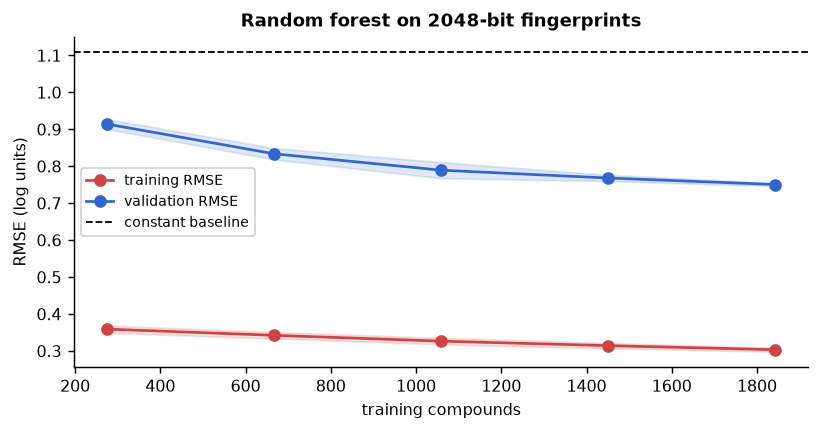

In [15]:
# Learning curve of the random forest on fingerprints (3-fold CV at five training sizes; ~25 s).
from sklearn.model_selection import learning_curve
sizes, tr_sc, va_sc = learning_curve(
    RandomForestRegressor(n_estimators=150, random_state=0, n_jobs=-1), X_fp, y,
    train_sizes=np.linspace(0.15, 1.0, 5), cv=KFold(3, shuffle=True, random_state=0),
    scoring="neg_root_mean_squared_error", random_state=0)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(sizes, -tr_sc.mean(1), "o-", color="#c44", label="training RMSE")
ax.fill_between(sizes, -tr_sc.mean(1) - tr_sc.std(1), -tr_sc.mean(1) + tr_sc.std(1), color="#c44", alpha=0.15)
ax.plot(sizes, -va_sc.mean(1), "o-", color="#36c", label="validation RMSE")
ax.fill_between(sizes, -va_sc.mean(1) - va_sc.std(1), -va_sc.mean(1) + va_sc.std(1), color="#36c", alpha=0.15)
ax.axhline(y.std(ddof=1), color="k", ls="--", lw=1, label="constant baseline")
ax.set_xlabel("training compounds"); ax.set_ylabel("RMSE (log units)")
ax.set_title("Random forest on 2048-bit fingerprints"); ax.legend(fontsize=7.5)
fig.tight_layout()
print("training sizes:", sizes)
print("validation RMSE:", np.round(-va_sc.mean(1), 3), "| training RMSE:", np.round(-tr_sc.mean(1), 3))

<p class="caption"><b>Figure 5.</b> Learning curve of the random forest on fingerprints. The training RMSE stays near 0.30–0.36 at every size — the forest can always fit its own training set almost perfectly — while the validation RMSE falls from about 0.91 at 276 compounds to about 0.75 at 1,842 and is <em>still falling</em> at the right-hand edge. The large persistent gap is the signature of a high-variance model, and the downward slope is the practical message: for this target, measuring more compounds would still buy accuracy. The dashed line is the constant baseline (1.11); even the smallest training set beats it.</p>

validation RMSE: [1.074 1.052 1.043 1.042 1.042] | training RMSE: [1.021 1.046 1.029 1.028 1.035]
gap at the largest size: 0.007 (forest: 0.447)


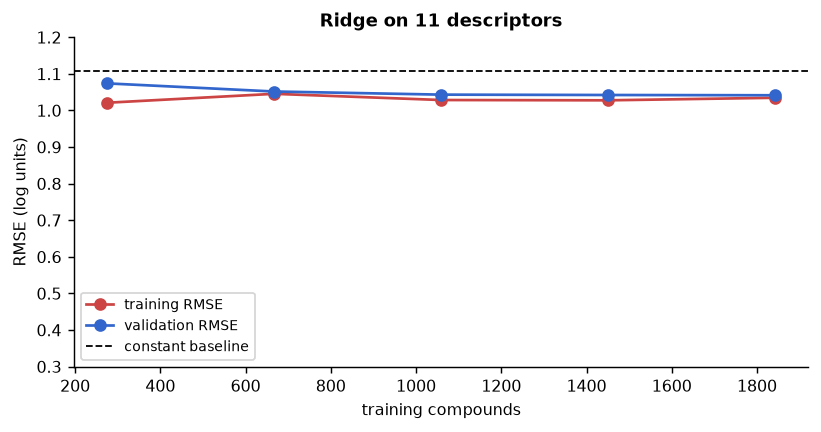

In [16]:
# The opposite regime: a rigid model on eleven descriptors.
sizes2, tr2, va2 = learning_curve(
    Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]), X_desc, y,
    train_sizes=np.linspace(0.15, 1.0, 5), cv=KFold(3, shuffle=True, random_state=0),
    scoring="neg_root_mean_squared_error", random_state=0)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(sizes2, -tr2.mean(1), "o-", color="#c44", label="training RMSE")
ax.plot(sizes2, -va2.mean(1), "o-", color="#36c", label="validation RMSE")
ax.axhline(y.std(ddof=1), color="k", ls="--", lw=1, label="constant baseline")
ax.set_ylim(0.3, 1.2); ax.set_xlabel("training compounds"); ax.set_ylabel("RMSE (log units)")
ax.set_title("Ridge on 11 descriptors"); ax.legend(fontsize=7.5)
fig.tight_layout()
print("validation RMSE:", np.round(-va2.mean(1), 3), "| training RMSE:", np.round(-tr2.mean(1), 3))
print("gap at the largest size: %.3f (forest: %.3f)"
      % (float(-va2.mean(1)[-1] + tr2.mean(1)[-1]), float(-va_sc.mean(1)[-1] + tr_sc.mean(1)[-1])))

<p class="caption"><b>Figure 6.</b> The same experiment for ridge on eleven descriptors. Here the two curves are almost on top of each other at about 1.04 RMSE from the first training size onwards: the gap at the largest size is under 0.02 log units, against roughly 0.45 for the forest. This is textbook underfitting — the model has already extracted everything eleven bulk properties contain, and no amount of extra data will move it. The decision implied by the two figures is therefore asymmetric: for the descriptor model, invest in features; for the fingerprint forest, invest in data.</p>

<div class="exercise"><h4>Exercise 2</h4>
<p>Redraw Figure 5 with <code>RandomForestRegressor(max_depth=4)</code> and with <code>max_depth=None, min_samples_leaf=20</code>. Which of the three settings has the smallest gap between the curves, which has the lowest validation RMSE, and are they the same setting? Write one sentence explaining, in terms of bias and variance, why they need not be.</p></div>

## 7. Error analysis: which compounds are wrong, and why

A single test metric is the beginning of the analysis, not the end. The questions that decide whether a model is usable are: *where* does it fail, is the failure systematic, and does it fail on the compounds you care about? We now use the held-out fifth for the first time.

In [17]:
# The held-out test set, scored once, with three metrics and the full prediction vector kept.
from scipy.stats import spearmanr
pred_te = rf_small.predict(X_fp[idx_te])
rmse_te = float(np.sqrt(mean_squared_error(y[idx_te], pred_te)))
r2_te = float(r2_score(y[idx_te], pred_te))
rho_te = float(spearmanr(y[idx_te], pred_te).statistic)
print("held-out test set (n = %d compounds, never used until now)" % len(idx_te))
print("  RMSE      = %.3f log units   (constant baseline: %.3f)" % (rmse_te, y[idx_tr].std(ddof=1)))
print("  MAE       = %.3f log units" % mean_absolute_error(y[idx_te], pred_te))
print("  R2        = %.3f" % r2_te)
print("  Spearman  = %.3f   (how well the ranking is reproduced)" % rho_te)

held-out test set (n = 553 compounds, never used until now)
  RMSE      = 0.679 log units   (constant baseline: 1.107)
  MAE       = 0.507 log units
  R2        = 0.629
  Spearman  = 0.798   (how well the ranking is reproduced)


The held-out numbers — RMSE about 0.68 log units, R² about 0.63, Spearman ρ about 0.80 — are slightly *better* than the cross-validated estimate of Section 4 (RMSE 0.76): a single test set is itself a random draw, and with 553 compounds the difference is partly the luck of which compounds landed in the test fifth. Unit 12 puts a confidence interval on that number instead of quoting it bare. Spearman ρ ≈ 0.80 against R² ≈ 0.63 says something else: the model orders compounds better than it places them, and for a project that uses it to *rank* candidates the ranking correlation is the more relevant figure.

### 7.1 The ranked error table

The standard diagnostic is a table of the worst predictions annotated with everything you know about those compounds: how many measurements stand behind the target, the replicate spread, molecular size and lipophilicity, whether the scaffold appeared in training, and how similar the nearest training compound is.

In [18]:
# Nearest-neighbour similarity of every test compound to the training set, then the ranked error table.
fps_tr = [fps[i] for i in idx_tr]
max_sim = np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], fps_tr)) for i in idx_te])
err = pd.DataFrame({
    "name": reg["pref_name"].to_numpy()[idx_te], "y": y[idx_te], "pred": pred_te,
    "residual": y[idx_te] - pred_te, "n_meas": reg["n_measurements"].to_numpy()[idx_te],
    "spread": reg["pActivity_range"].to_numpy()[idx_te], "MolWt": reg["MolWt"].to_numpy()[idx_te],
    "MolLogP": reg["MolLogP"].to_numpy()[idx_te], "max_sim_train": max_sim,
    "new_scaffold": unseen_scaffold})
err["abs_err"] = err["residual"].abs()
worst = err.sort_values("abs_err", ascending=False).head(12)
print("median nearest-neighbour Tanimoto similarity to training: %.3f" % np.median(max_sim))
worst[["y", "pred", "residual", "n_meas", "spread", "MolWt", "MolLogP", "max_sim_train", "new_scaffold"]].round(2)

median nearest-neighbour Tanimoto similarity to training: 0.776


,y,pred,residual,n_meas,spread,MolWt,MolLogP,max_sim_train,new_scaffold
234,5.13,7.59,-2.46,2,0.0,462.51,4.31,0.77,True
317,7.89,5.60,2.28,1,0.0,339.38,2.98,0.53,True
247,8.70,6.56,2.14,1,0.0,473.37,4.49,0.47,True
486,5.03,7.11,-2.08,1,0.0,333.39,3.64,0.80,True
392,4.87,6.87,-2.00,1,0.0,392.38,3.28,0.41,True
246,6.30,8.29,-1.99,1,0.0,378.43,2.72,0.81,False
7,4.75,6.72,-1.96,1,0.0,474.57,4.72,0.28,True
321,4.00,5.96,-1.96,1,0.0,334.43,2.74,0.82,True
116,3.80,5.70,-1.90,1,0.0,252.28,3.21,0.67,True
121,8.15,6.28,1.87,1,0.0,373.82,3.77,0.67,False


<p class="caption"><b>Table (Section 7.1).</b> The twelve worst-predicted held-out compounds. Three patterns are visible and all three are chemically meaningful. (i) Every one of them is wrong by between about 1.8 and 2.5 log units — a factor of 60 to 300 in potency — while the typical error is 0.5; the error distribution has a heavy tail rather than being uniformly mediocre. (ii) Almost all of them rest on a <em>single</em> measurement (<code>n_meas</code> = 1, <code>spread</code> = 0), so part of what we are calling model error is unreplicated experimental error. (iii) Most carry a scaffold absent from training and several have a nearest training neighbour below Tanimoto 0.5, i.e. they are outside the region of chemical space the model learned — the applicability-domain question of Unit 17<sup class="c"><a href="#r22">[22]</a></sup>. The largest error of all (observed 5.13, predicted 7.59) is a compound that <em>looks</em> like a potent series member and is not: an activity cliff<sup class="c"><a href="#r28">[28]</a></sup>, the irreducible failure mode of similarity-based prediction.</p>

mean residual for weak compounds (y < 5.5, n=106): -0.81
mean residual for potent compounds (y > 7.5, n=111): +0.59


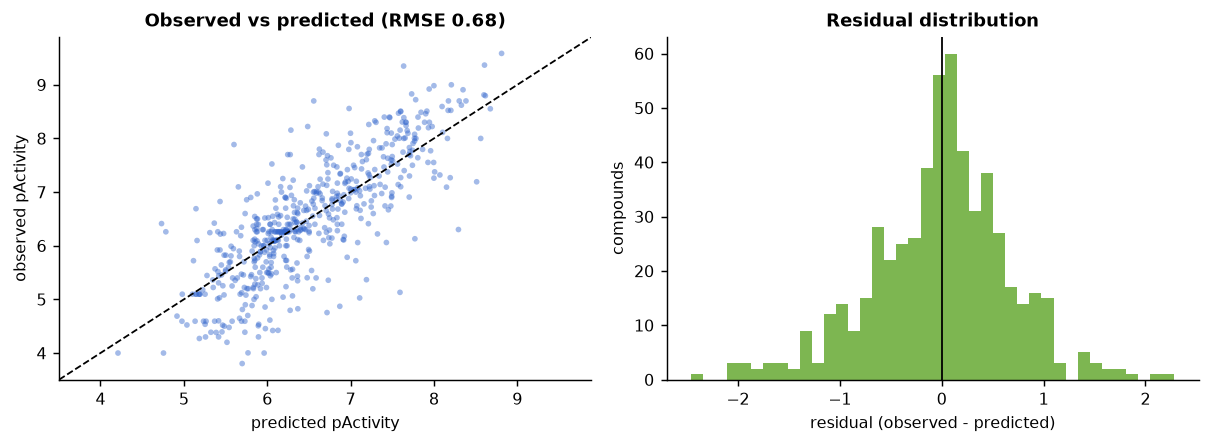

In [19]:
# Where the errors live: residuals against prediction, and the error distribution.
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5))
axes[0].scatter(pred_te, y[idx_te], s=10, alpha=0.45, color="#36c", edgecolor="none")
lims = [y[idx_te].min() - 0.3, y[idx_te].max() + 0.3]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("predicted pActivity"); axes[0].set_ylabel("observed pActivity")
axes[0].set_title(f"Observed vs predicted (RMSE {rmse_te:.2f})")
axes[1].hist(err["residual"], bins=40, color="#6a3", alpha=0.85)
axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("residual (observed - predicted)"); axes[1].set_ylabel("compounds")
axes[1].set_title("Residual distribution")
fig.tight_layout()
lo, hi = y[idx_te] < 5.5, y[idx_te] > 7.5
print("mean residual for weak compounds (y < 5.5, n=%d): %+.2f" % (lo.sum(), err.loc[lo.nonzero()[0], 'residual'].mean()))
print("mean residual for potent compounds (y > 7.5, n=%d): %+.2f" % (hi.sum(), err.loc[hi.nonzero()[0], 'residual'].mean()))

<p class="caption"><b>Figure 7.</b> Left: observed against predicted pActivity for the 553 held-out compounds, with the identity line. The cloud is tilted — weak compounds are predicted too potent (mean residual about −0.8 below pActivity 5.5) and potent ones too weak (about +0.6 above 7.5). This is <strong>regression to the mean</strong>: a squared-error model shrinks predictions towards the centre, most strongly where data are thinnest, so the model is a ranking device rather than a potency calculator at the extremes. Right: the residual distribution, centred on zero, with the heavy tails documented above.</p>

### 7.2 Error as a function of distance to the training set

The single most useful slice of the error is by similarity to the training set, because it tells you whether the model should be trusted on a *new* compound at all.

                          n   RMSE  median_sim
max_sim_train                                 
Q1 (most dissimilar)  140.0  0.807       0.574
Q2                    138.0  0.661       0.736
Q3                    137.0  0.616       0.808
Q4 (most similar)     138.0  0.610       0.925
RMSE, scaffold seen in training (n=341)   : 0.596
RMSE, scaffold NEW to the model (n=212)   : 0.794


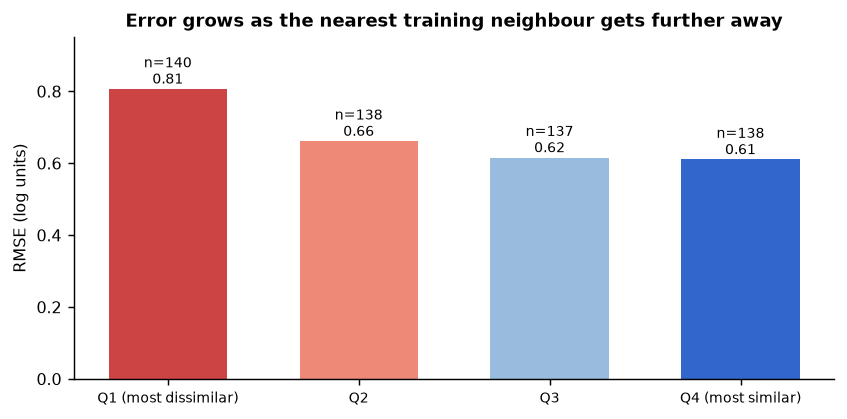

In [20]:
# RMSE by quartile of nearest-neighbour similarity, and by whether the scaffold was seen in training.
q = pd.qcut(err["max_sim_train"], 4, labels=["Q1 (most dissimilar)", "Q2", "Q3", "Q4 (most similar)"])
by_q = err.groupby(q, observed=True).apply(
    lambda g: pd.Series({"n": len(g), "RMSE": float(np.sqrt((g["residual"] ** 2).mean())),
                         "median_sim": float(g["max_sim_train"].median())}), include_groups=False)
fig, ax = plt.subplots(figsize=(6.6, 3.3))
ax.bar(range(4), by_q["RMSE"], color=["#c44", "#e87", "#9bd", "#36c"], width=0.62)
for i, (n, r) in enumerate(zip(by_q["n"], by_q["RMSE"])):
    ax.text(i, r + 0.015, f"n={int(n)}\n{r:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(range(4)); ax.set_xticklabels(by_q.index, fontsize=8)
ax.set_ylabel("RMSE (log units)"); ax.set_ylim(0, 0.95)
ax.set_title("Error grows as the nearest training neighbour gets further away")
fig.tight_layout()
m = err["new_scaffold"].to_numpy()
print(by_q.round(3).to_string())
print("RMSE, scaffold seen in training (n=%d)   : %.3f" % ((~m).sum(), np.sqrt((err.loc[~m, 'residual'] ** 2).mean())))
print("RMSE, scaffold NEW to the model (n=%d)   : %.3f" % (m.sum(), np.sqrt((err.loc[m, 'residual'] ** 2).mean())))

<p class="caption"><b>Figure 8.</b> Held-out RMSE by quartile of nearest-neighbour Tanimoto similarity to the training set. The most dissimilar quartile (median similarity about 0.6) is predicted with RMSE about 0.81, the most similar quartile (median about 0.90) with about 0.61 — a 25% difference purely as a function of how close the nearest analogue is. The printed lines make the same point with scaffolds: RMSE about 0.60 for ring frameworks already in training, about 0.79 for new ones. <strong>This comparison is the argument of Unit 12 in miniature</strong>: a random split mixes the two populations and reports their average, while the real question — "will this model work on a chemotype we have not seen?" — is answered only by the right-hand bar.</p>

<div class="box warn"><h4>What to do with an error analysis</h4>
<p>An error analysis is not a confession, it is a specification. This one says: report the model as a ranking tool with an expected error near 0.5–0.6 log units inside known chemotypes and near 0.8 outside them; flag any prediction whose nearest training neighbour is below Tanimoto 0.5; re-measure the worst twelve compounds before calling them activity cliffs, since most rest on a single unreplicated measurement; and do not use the model for absolute potency at the extremes.</p></div>

## 8. The leakage catalogue

**Leakage** is the use, during training or model selection, of information that would not be available at prediction time — or the use of the evaluation data to make any decision at all. Its signature is a model that performs beautifully in the paper and poorly in the laboratory. It has five standard forms<sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r3">[3]</a></sup>, to which chemistry adds its own biases in how benchmark sets are assembled<sup class="c"><a href="#r29">[29]</a></sup>; tuning on the same data used for assessment is a sixth, measured in Unit 12<sup class="c"><a href="#r4">[4]</a></sup>.

1. **Preprocessing fitted on all the data.** Scaling, imputation, encoding or PCA computed before the split. Usually a small effect, always avoidable by using a `Pipeline`.
2. **Supervised feature selection before the split.** Choosing features by their correlation with the target on the whole dataset. This is the dangerous one, because the selection itself is a model fitted to the test labels. Ambroise and McLachlan showed on microarray data that it can turn pure noise into an apparently excellent classifier<sup class="c"><a href="#r18">[18]</a></sup>.
3. **Duplicates across the split.** The same compound (or patient, or near-identical analogue) present in both training and test. Our curation collapsed exact duplicates by InChIKey, but analogue series are a softer version of the same problem — the subject of the scaffold split.
4. **Target-derived features.** A feature computed from the target, or from something downstream of it. In our table `pActivity_min`, `pActivity_max` and `pActivity_sd` are of this kind: innocent-looking provenance columns that are functions of the answer.
5. **Temporal leakage.** Training on data from after the prediction time — publications, assay campaigns or clinical visits that would not have existed yet. Sheridan's time-split cross-validation<sup class="c"><a href="#r5">[5]</a></sup> is the remedy; Unit 12 implements it.

### 8.1 Measuring the optimism of leaked feature selection

The experiment: select the 50 fingerprint bits most correlated with pActivity, scale them, and fit a ridge regression — once with the selection and scaling performed on the whole dataset before cross-validation (the naive version), once with both steps inside the pipeline so that they are refitted in each fold (the correct version). Everything else is identical. We repeat it at four sample sizes, because the severity of this leak depends on how many rows there are per candidate feature.

In [21]:
# The canonical leakage experiment: supervised feature selection inside vs outside the cross-validation.
from sklearn.feature_selection import SelectKBest, f_regression
rows = []
for n in [150, 400, 1000, len(y)]:
    sub = np.random.RandomState(0).choice(len(y), n, replace=False)
    Xs, ys = X_fp[sub], y[sub]
    cvn = KFold(5, shuffle=True, random_state=0)
    # NAIVE: select the 50 best bits and scale using ALL n rows (test labels included), then cross-validate
    Xsel = SelectKBest(f_regression, k=50).fit_transform(Xs, ys)
    naive = cross_validate(Ridge(alpha=1.0), StandardScaler().fit_transform(Xsel), ys, cv=cvn, scoring="r2")
    # CORRECT: identical steps, refitted inside each training fold
    good = cross_validate(Pipeline([("sel", SelectKBest(f_regression, k=50)),
                                   ("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]), Xs, ys, cv=cvn, scoring="r2")
    rows.append({"n_compounds": n, "naive_R2": naive["test_score"].mean(),
                 "correct_R2": good["test_score"].mean(),
                 "optimism": naive["test_score"].mean() - good["test_score"].mean()})
leak = pd.DataFrame(rows).round(3)
leak

,n_compounds,naive_R2,correct_R2,optimism
0,150,0.152,-0.344,0.496
1,400,0.335,0.254,0.081
2,1000,0.367,0.325,0.042
3,2764,0.315,0.290,0.025


<p class="caption"><b>Table (Section 8.1).</b> The optimism of selecting features outside the cross-validation, as a function of sample size. With 150 compounds and 2,048 candidate bits the naive protocol reports R² ≈ 0.15 while the honest protocol reports R² ≈ −0.34 — the "model" is in fact worse than predicting the mean, and the naive number is pure selection bias worth 0.50 R² units. The optimism falls to about 0.08 at n = 400, 0.04 at n = 1,000 and 0.03 at the full 2,764 compounds. The lesson is not "leakage is small on big datasets"; it is that <em>the same wrong code produces a catastrophic lie on a small dataset and a mild one on a large dataset</em>, and small datasets are exactly what a thesis project has.</p>

pure noise  : naive R2 = +0.462 | correct R2 = -0.243


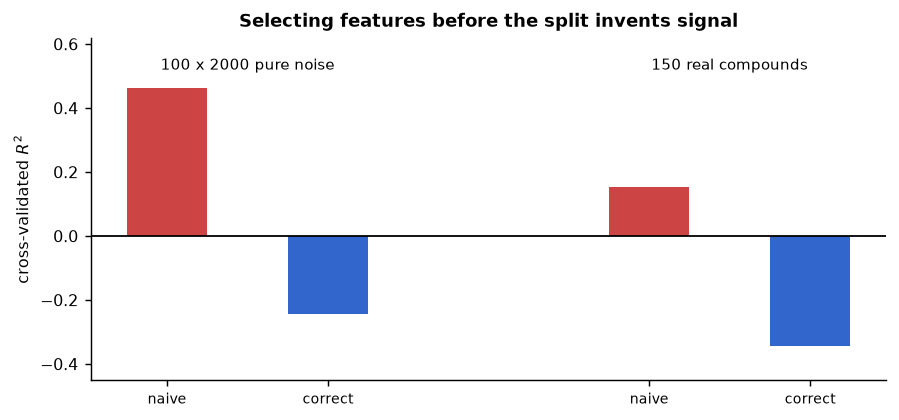

In [22]:
# The same experiment on pure noise, where the honest answer is known to be zero.
rng = np.random.RandomState(0)
X_noise, y_noise = rng.normal(size=(100, 2000)), rng.normal(size=100)
cvn = KFold(5, shuffle=True, random_state=0)
sel_all = SelectKBest(f_regression, k=20).fit(X_noise, y_noise)
naive_noise = cross_validate(Ridge(), sel_all.transform(X_noise), y_noise, cv=cvn, scoring="r2")["test_score"].mean()
good_noise = cross_validate(Pipeline([("sel", SelectKBest(f_regression, k=20)), ("m", Ridge())]),
                            X_noise, y_noise, cv=cvn, scoring="r2")["test_score"].mean()
fig, ax = plt.subplots(figsize=(7.0, 3.3))
ax.bar([0, 1], [naive_noise, good_noise], color=["#c44", "#36c"], width=0.5)
ax.bar([3, 4], [float(leak.loc[0, "naive_R2"]), float(leak.loc[0, "correct_R2"])], color=["#c44", "#36c"], width=0.5)
ax.axhline(0, color="k", lw=1)
ax.set_xticks([0, 1, 3, 4]); ax.set_xticklabels(["naive", "correct", "naive", "correct"], fontsize=8)
ax.set_ylabel("cross-validated $R^2$")
ax.text(0.5, 0.52, "100 x 2000 pure noise", ha="center", fontsize=8.5)
ax.text(3.5, 0.52, "150 real compounds", ha="center", fontsize=8.5)
ax.set_ylim(-0.45, 0.62); ax.set_title("Selecting features before the split invents signal")
fig.tight_layout()
print("pure noise  : naive R2 = %+.3f | correct R2 = %+.3f" % (naive_noise, good_noise))

<p class="caption"><b>Figure 9.</b> Leakage demonstrated where the truth is known. On the left, a matrix of 100 rows and 2,000 columns of Gaussian noise with a Gaussian target: there is nothing to learn, and the honest pipeline correctly reports R² ≈ −0.24, while selecting the 20 "best" columns on the full data first reports R² ≈ +0.46 — a confident model of nothing. On the right, the n = 150 row of the previous table, showing the same mechanism on real chemistry. Any published model whose preprocessing touched the test labels is reporting a number from the red bars.</p>

### 8.2 Target-derived features

The fourth leak needs no cross-validation subtlety to be fatal. The curated table carries `pActivity_min`, `pActivity_max` and `pActivity_sd`, which describe the replicate measurements from which the target was computed. They are legitimate provenance columns and illegitimate features.

In [23]:
# What happens when a provenance column is left in the feature matrix by accident.
X_leaky = np.column_stack([X_desc, reg[["pActivity_min", "pActivity_max", "pActivity_sd"]].fillna(0).to_numpy()])
s_leak = cross_validate(Pipeline([("sc", StandardScaler()), ("m", Ridge())]), X_leaky, y, cv=cv5,
                        scoring=["r2", "neg_root_mean_squared_error"])
s_ok = cross_validate(Pipeline([("sc", StandardScaler()), ("m", Ridge())]), X_desc, y, cv=cv5,
                      scoring=["r2", "neg_root_mean_squared_error"])
print("descriptors only                  : R2 = %.3f | RMSE = %.3f"
      % (s_ok["test_r2"].mean(), -s_ok["test_neg_root_mean_squared_error"].mean()))
print("descriptors + provenance columns  : R2 = %.3f | RMSE = %.3f"
      % (s_leak["test_r2"].mean(), -s_leak["test_neg_root_mean_squared_error"].mean()))
print("\nfor compounds with a single measurement, pActivity_min == pActivity_max == pActivity:",
      bool(np.allclose(reg.loc[reg['n_measurements'] == 1, 'pActivity_min'],
                       reg.loc[reg['n_measurements'] == 1, 'pActivity'])))

descriptors only                  : R2 = 0.112 | RMSE = 1.042
descriptors + provenance columns  : R2 = 0.996 | RMSE = 0.067

for compounds with a single measurement, pActivity_min == pActivity_max == pActivity: True


R² jumps from 0.11 to 0.996 and RMSE collapses from 1.04 to 0.07 log units. No cross-validation scheme protects against this: the leak is not in the protocol but in the matrix, since for compounds measured once `pActivity_min` *is* the target. A result this good is always a bug, and the habit that catches it is to read the feature columns aloud and ask of each: *would I know this value for a molecule never tested?*

<div class="box warn"><h4>The leakage checklist</h4>
<p>Before reporting any model: (1) is every learned preprocessing step inside a <code>Pipeline</code>? (2) was any feature chosen, any threshold set, any hyperparameter tuned using the test data? (3) can the same entity (compound, patient, trajectory) appear on both sides of the split? (4) could any feature be computed only <em>after</em> the target was known? (5) does the model still fail on shuffled labels? (6) is the reported score better than the field's typical result for this kind of data — and if so, why?</p></div>

## 9. The model card

A model that leaves your laptop needs a short document stating what it is, what it was trained on, how it was evaluated and where it should not be used — a model card<sup class="c"><a href="#r17">[17]</a></sup>, whose biomedical equivalents are the DOME recommendations<sup class="c"><a href="#r15">[15]</a></sup> and TRIPOD+AI<sup class="c"><a href="#r16">[16]</a></sup> and whose QSAR version is the OECD validation principles<sup class="c"><a href="#r24">[24]</a></sup> elaborated by Tropsha<sup class="c"><a href="#r7">[7]</a></sup>. The next cell writes the card from the objects in memory, so it cannot drift from the model it describes.

In [24]:
# A model card generated from the run itself, not from memory.
card = {
 "model": "RandomForestRegressor(n_estimators=300, random_state=0) on Morgan(r=2, 2048 bit) fingerprints",
 "task": "regression of pActivity (-log10 M) for ROCK1 (CHEMBL3231) inhibitors",
 "unit of prediction": "one standardised parent structure (InChIKey)",
 "training data": f"{len(idx_tr)} compounds from the curated ChEMBL snapshot (exact measurements only)",
 "excluded": f"{int(df['censored'].sum())} censored compounds (all measurements '>' or '<')",
 "split": "random 80/20 by compound, random_state=0; inner 5-fold CV for all comparisons",
 "test performance": f"RMSE {rmse_te:.3f}, MAE {mean_absolute_error(y[idx_te], pred_te):.3f}, "
                     f"R2 {r2_te:.3f}, Spearman {rho_te:.3f} on {len(idx_te)} held-out compounds",
 "baseline": f"predicting the training mean gives RMSE {y[idx_tr].std(ddof=1):.3f}",
 "performance by applicability": f"RMSE {np.sqrt((err.loc[~m,'residual']**2).mean()):.2f} for known scaffolds vs "
                                 f"{np.sqrt((err.loc[m,'residual']**2).mean()):.2f} for unseen scaffolds",
 "known limitations": "regresses to the mean at the extremes; errors above 1.5 log units concentrate on "
                      "single-measurement compounds and on structures with nearest-neighbour Tanimoto < 0.5",
 "intended use": "ranking of analogues inside known ROCK1 chemotypes; NOT absolute potency prediction",
 "sanity checks": f"shuffled-label R2 = {s_shuf['test_score'].mean():+.3f}; no preprocessing fitted outside a fold",
}
for k, v in card.items():
    print(f"{k:28s}: {v}")

model                       : RandomForestRegressor(n_estimators=300, random_state=0) on Morgan(r=2, 2048 bit) fingerprints
task                        : regression of pActivity (-log10 M) for ROCK1 (CHEMBL3231) inhibitors
unit of prediction          : one standardised parent structure (InChIKey)
training data               : 2211 compounds from the curated ChEMBL snapshot (exact measurements only)
excluded                    : 1516 censored compounds (all measurements '>' or '<')
split                       : random 80/20 by compound, random_state=0; inner 5-fold CV for all comparisons
test performance            : RMSE 0.679, MAE 0.507, R2 0.629, Spearman 0.798 on 553 held-out compounds
baseline                    : predicting the training mean gives RMSE 1.107
performance by applicability: RMSE 0.60 for known scaffolds vs 0.79 for unseen scaffolds
known limitations           : regresses to the mean at the extremes; errors above 1.5 log units concentrate on single-measurement compoun

Everything in the card is a number this notebook produced, and every entry answers a question a referee asks. The two entries that distinguish a careful card from a decorative one are "performance by applicability" — performance split by whether the compound resembles the training data — and "intended use", which is where you write down the thing the model is *not* for.

<div class="box bridge"><h4>Bridge — where this unit sits</h4>
<p>The neighbouring units supply what this one simplified. <a href="../U9_Linear_Models/index.html">Unit 9</a> explains the ridge baseline; <a href="../U12_Validation/index.html">Unit 12</a> replaces the random split by the split taxonomy and puts confidence intervals on every number above; <a href="../U13_Features_Dimensionality/index.html">Unit 13</a> does feature selection properly, with stability across folds; <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a> tunes the forest and its boosted cousins under a budget; <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> turns "similarity below 0.5" into a calibrated applicability domain; <a href="../U23_Communication/index.html">Unit 23</a> turns the model card into a Methods section. The algorithms themselves are the subject of the artificial-intelligence course <a href="../../BGM411/Python/index.html">BGM411</a>; the chemistry of the representation is <a href="../../Cheminformatics/U5_Descriptors_Fingerprints/index.html">Unit 5 of the cheminformatics course</a> and the curation behind the table is <a href="../../Cheminformatics/U7_Data_Curation/index.html">its Unit 7</a> with <a href="../U6_Data_Quality/index.html">Unit 6</a> here. For the structural side of ROCK1 see <a href="../../BGM324/03_Molecular_Docking/index.html">BGM324 Unit 3</a>.</p></div>

## 10. Summary

You should now be able to explain, without notes:

- the seven decisions of a supervised project, and why only one is about the algorithm;
- why the unit of prediction must be the entity you will be asked to predict (compound, not measurement; patient, not tissue site);
- when a question is a regression, a classification at a stated threshold, or a ranking problem, with the metric for each;
- what a `Pipeline` and a `ColumnTransformer` guarantee, how to write a custom transformer, and which featurisation steps are safe outside a pipeline;
- why a score is meaningless without a baseline, and which three baselines to compute;
- how to read a learning curve and decide between more data and more capacity;
- how to turn an error analysis into a statement about the applicability of the model;
- the five leakage sources, the optimism each produces, and the checklist that catches them;
- what belongs in a model card.

The single number to take away: on this dataset, selecting 50 of 2,048 features outside the cross-validation inflates R² by about 0.50 at n = 150 and by about 0.03 at n = 2,764 — and on pure noise it manufactures an R² of about 0.46 out of nothing.

## 11. Self-assessment

<details><summary>1. A colleague reports R² = 0.72 for a QSAR model. What are the first three questions you ask?</summary>Computed on what — cross-validation or a held-out set, under which split? Against which baseline? And what is the unit of prediction, compounds or measurements? Without those three the number is not interpretable.</details>

<details><summary>2. Why is a 1-nearest-neighbour model on Tanimoto similarity a more meaningful baseline than the mean?</summary>Because it is what a chemist does without a computer: find the closest known analogue and assume similar potency. Beating 1-NN shows the model has learned something beyond "similar molecules have similar activity" — here 1-NN reaches R² ≈ 0.25 against the forest's ≈ 0.53.</details>

<details><summary>3. You standardise the full data matrix and then split. How bad is it, and how would you find out?</summary>Usually mild, because scaling is unsupervised and a mean from 80% of the rows differs little from one over 100%. You find out by running both protocols, as in Section 8.1. Avoid it anyway: the same habit applied to a supervised step is catastrophic.</details>

<details><summary>4. Which of these can safely be computed before the split: a Morgan fingerprint, a standard scaler, a PCA rotation, a molecular weight, a filter keeping bits present in >1% of compounds?</summary>The fingerprint and the molecular weight — row-wise functions of one molecule. The scaler, the PCA and the frequency filter learn from the set as a whole and must be fitted inside the training fold.</details>

<details><summary>5. Training RMSE 0.30, validation RMSE 0.75, validation curve still falling. What next?</summary>Acquire more compounds: the curve has not plateaued. Reducing variance would also narrow the gap, but the slope says data is the cheapest remaining gain. Contrast Figure 6, where the curves converged and extra data is worthless.</details>

<details><summary>6. Your test R² is higher than your cross-validated R². Is something wrong?</summary>Not necessarily. A single test set of 553 compounds is one random draw with a standard error of a few hundredths, and cross-validation trains on less data, so it is slightly pessimistic. The response is a confidence interval, not a comparison of two point estimates — Unit 12.</details>

<details><summary>7. Why does the model predict weak compounds as too potent and potent compounds as too weak?</summary>Regression to the mean: minimising squared error against a bell-shaped target shrinks predictions towards the centre, most strongly where data are sparse. Absolute potency at the extremes is therefore unreliable while the ranking stays informative — Spearman ρ ≈ 0.80 with R² ≈ 0.63.</details>

<details><summary>8. A feature called <code>n_assays</code> improves your model substantially. Should you keep it?</summary>No. It is known only because the compound was tested, so it cannot be computed for a new molecule, and it correlates with potency because interesting compounds get re-tested. Same family as <code>pActivity_min</code>, which pushed R² to 0.996.</details>

<details><summary>9. What does a negative cross-validated R² mean?</summary>That the model predicts held-out data worse than the training mean. It is the correct result for a model fitted to noise (about −0.24 in Section 8.1) and common on small datasets; R² is not bounded below by zero out of sample.</details>

<details><summary>10. How would you convert this regression into the ranking problem a screening campaign needs?</summary>Keep the pipeline but evaluate with ranking metrics on the top slice: enrichment factor at 1%, BEDROC, Spearman ρ among the predicted top 100 (Unit 19). The change is in decisions 1, 6 and 7 — question, metric, error analysis — not in the algorithm.</details>

<details><summary>11. Your pipeline gives R² = 0.93 where the literature reports 0.6. What do you do before celebrating?</summary>Assume leakage and run the checklist: which feature columns could not be known before the target; duplicates straddling folds; selection or tuning that saw the validation folds; shuffled labels. Results far above the field's norm are usually a bug.</details>

<details><summary>12. Why does the model card record performance separately for seen and unseen scaffolds?</summary>Because the user is almost always asking about the unseen case. RMSE is about 0.60 within known frameworks and 0.79 on new ones; quoting only the pooled 0.68 overstates performance for the prospective use.</details>

## Glossary

<dl class="gloss">
<dt>Baseline</dt><dd>A deliberately simple predictor (the mean, the majority class, the nearest neighbour, a regularised linear model) whose score any real model must beat before it is worth discussing.</dd>
<dt>Censored measurement</dt><dd>A record stating only that a value lies above or below a bound ("IC50 > 10 µM"); usable as an inequality, not as a number.</dd>
<dt>ColumnTransformer</dt><dd>A scikit-learn object that applies a different sub-pipeline to each group of columns and concatenates the results.</dd>
<dt>Descriptor</dt><dd>A single interpretable number computed from a structure (weight, lipophilicity, polar surface area, ring count...).</dd>
<dt>Error analysis</dt><dd>Study of which rows a model predicts worst and why; usually a ranked residual table annotated with domain information.</dd>
<dt>Learning curve</dt><dd>Training and validation error against training-set size; diagnoses underfitting (converged, high) versus overfitting (wide, persistent gap).</dd>
<dt>Leakage</dt><dd>Use at training or selection time of information unavailable at prediction time, including any use of the evaluation data to make a decision.</dd>
<dt>MAE / RMSE</dt><dd>Mean absolute error and root mean squared error; RMSE squares residuals and is dominated by the worst cases.</dd>
<dt>Model card</dt><dd>A short document stating what a model is, what it was trained and evaluated on, how it performs by subgroup, and where it must not be used.</dd>
<dt>Morgan fingerprint (ECFP)</dt><dd>A binary vector (here 2,048 bits) recording which circular atom environments a molecule contains.</dd>
<dt>pActivity</dt><dd>−log<sub>10</sub> of an activity concentration in molar; larger means more potent, one unit is tenfold.</dd>
<dt>Pipeline</dt><dd>A single estimator chaining transformers and a final predictor so that <code>fit</code> fits every step on training data only.</dd>
<dt>R²</dt><dd>One minus residual over total sum of squares; relative to the variance of the evaluation set, and negative out of sample for a model worse than the mean.</dd>
<dt>Regression to the mean</dt><dd>The shrinkage of squared-error predictions towards the centre of the target distribution, seen as a tilt against the identity line.</dd>
<dt>Scaffold (Bemis–Murcko)</dt><dd>Ring systems plus linkers, side chains removed; a computable proxy for "chemical series".</dd>
<dt>Tanimoto (Jaccard) similarity</dt><dd>Shared bits over union of bits between two fingerprints; the standard similarity for binary substructure vectors.</dd>
<dt>Transformer (scikit-learn)</dt><dd>An object with <code>fit</code> and <code>transform</code> that learns parameters from training data and applies them unchanged to new data.</dd>
<dt>Unit of prediction</dt><dd>The entity one row represents and the model is asked to predict; must be the entity the question is about.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: machine learning in Python. <em>J Mach Learn Res</em>. 2011;12:2825-2830. <a href="https://doi.org/10.48550/arXiv.1201.0490">doi:10.48550/arXiv.1201.0490</a></li>
<li id="r2">Kaufman S, Rosset S, Perlich C, Stitelman O. Leakage in data mining: formulation, detection, and avoidance. <em>ACM Trans Knowl Discov Data</em>. 2012;6(4):15. <a href="https://doi.org/10.1145/2382577.2382579">doi:10.1145/2382577.2382579</a></li>
<li id="r3">Kapoor S, Narayanan A. Leakage and the reproducibility crisis in machine-learning-based science. <em>Patterns</em>. 2023;4(9):100804. <a href="https://doi.org/10.1016/j.patter.2023.100804">doi:10.1016/j.patter.2023.100804</a></li>
<li id="r4">Varma S, Simon R. Bias in error estimation when using cross-validation for model selection. <em>BMC Bioinformatics</em>. 2006;7:91. <a href="https://doi.org/10.1186/1471-2105-7-91">doi:10.1186/1471-2105-7-91</a></li>
<li id="r5">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783-790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r6">Whalen S, Schreiber J, Noble WS, Pollard KS. Navigating the pitfalls of applying machine learning in genomics. <em>Nat Rev Genet</em>. 2022;23(3):169-181. <a href="https://doi.org/10.1038/s41576-021-00434-9">doi:10.1038/s41576-021-00434-9</a></li>
<li id="r7">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6-7):476-488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r8">Golbraikh A, Tropsha A. Beware of q2! <em>J Mol Graph Model</em>. 2002;20(4):269-276. <a href="https://doi.org/10.1016/S1093-3263(01)00123-1">doi:10.1016/S1093-3263(01)00123-1</a></li>
<li id="r9">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r10">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742-754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r11">Hunter JD. Matplotlib: a 2D graphics environment. <em>Comput Sci Eng</em>. 2007;9(3):90-95. <a href="https://doi.org/10.1109/MCSE.2007.55">doi:10.1109/MCSE.2007.55</a></li>
<li id="r12">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887-2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r13">Kalliokoski T, Kramer C, Vulpetti A, Gedeck P. Comparability of mixed IC50 data - a statistical analysis. <em>PLoS ONE</em>. 2013;8(4):e61007. <a href="https://doi.org/10.1371/journal.pone.0061007">doi:10.1371/journal.pone.0061007</a></li>
<li id="r14">Landrum GA, Riniker S. Combining IC50 or Ki values from different sources is a source of significant noise. <em>J Chem Inf Model</em>. 2024;64(5):1560-1567. <a href="https://doi.org/10.1021/acs.jcim.4c00049">doi:10.1021/acs.jcim.4c00049</a></li>
<li id="r15">Walsh I, Fishman D, Garcia-Gasulla D, et al. DOME: recommendations for supervised machine learning validation in biology. <em>Nat Methods</em>. 2021;18(10):1122-1127. <a href="https://doi.org/10.1038/s41592-021-01205-4">doi:10.1038/s41592-021-01205-4</a></li>
<li id="r16">Collins GS, Moons KGM, Dhiman P, et al. TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. <em>BMJ</em>. 2024;385:e078378. <a href="https://doi.org/10.1136/bmj-2023-078378">doi:10.1136/bmj-2023-078378</a></li>
<li id="r17">Mitchell M, Wu S, Zaldivar A, et al. Model cards for model reporting. In: <em>Proc. Conf. on Fairness, Accountability, and Transparency (FAT* '19)</em>. ACM; 2019:220-229. <a href="https://doi.org/10.1145/3287560.3287596">doi:10.1145/3287560.3287596</a></li>
<li id="r18">Ambroise C, McLachlan GJ. Selection bias in gene extraction on the basis of microarray gene-expression data. <em>Proc Natl Acad Sci USA</em>. 2002;99(10):6562-6566. <a href="https://doi.org/10.1073/pnas.102102699">doi:10.1073/pnas.102102699</a></li>
<li id="r19">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45:5-32. <a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r20">Svetnik V, Liaw A, Tong C, Culberson JC, Sheridan RP, Feuston BP. Random forest: a classification and regression tool for compound classification and QSAR modeling. <em>J Chem Inf Comput Sci</em>. 2003;43(6):1947-1958. <a href="https://doi.org/10.1021/ci034160g">doi:10.1021/ci034160g</a></li>
<li id="r21">Hoerl AE, Kennard RW. Ridge regression: biased estimation for nonorthogonal problems. <em>Technometrics</em>. 1970;12(1):55-67. <a href="https://doi.org/10.1080/00401706.1970.10488634">doi:10.1080/00401706.1970.10488634</a></li>
<li id="r22">Mathea M, Klingspohn W, Baumann K. Chemoinformatic classification methods and their applicability domain. <em>Mol Inform</em>. 2016;35(5):160-180. <a href="https://doi.org/10.1002/minf.201501019">doi:10.1002/minf.201501019</a></li>
<li id="r23">Hawkins DM. The problem of overfitting. <em>J Chem Inf Comput Sci</em>. 2004;44(1):1-12. <a href="https://doi.org/10.1021/ci0342472">doi:10.1021/ci0342472</a></li>
<li id="r24">Gramatica P. Principles of QSAR models validation: internal and external. <em>QSAR Comb Sci</em>. 2007;26(5):694-701. <a href="https://doi.org/10.1002/qsar.200610151">doi:10.1002/qsar.200610151</a></li>
<li id="r25">Bickerton GR, Paolini GV, Besnard J, Muresan S, Hopkins AL. Quantifying the chemical beauty of drugs. <em>Nat Chem</em>. 2012;4:90-98. <a href="https://doi.org/10.1038/nchem.1243">doi:10.1038/nchem.1243</a></li>
<li id="r26">Harris CR, Millman KJ, van der Walt SJ, et al. Array programming with NumPy. <em>Nature</em>. 2020;585:357-362. <a href="https://doi.org/10.1038/s41586-020-2649-2">doi:10.1038/s41586-020-2649-2</a></li>
<li id="r27">Todeschini R, Consonni V. <em>Molecular Descriptors for Chemoinformatics</em>. 2nd ed. Wiley-VCH; 2009. <a href="https://doi.org/10.1002/9783527628766">doi:10.1002/9783527628766</a></li>
<li id="r28">Stumpfe D, Bajorath J. Exploring activity cliffs in medicinal chemistry. <em>J Med Chem</em>. 2012;55(7):2932-2942. <a href="https://doi.org/10.1021/jm201706b">doi:10.1021/jm201706b</a></li>
<li id="r29">Sieg J, Flachsenberg F, Rarey M. In need of bias control: evaluating chemical data for machine learning in structure-based virtual screening. <em>J Chem Inf Model</em>. 2019;59(3):947-961. <a href="https://doi.org/10.1021/acs.jcim.8b00712">doi:10.1021/acs.jcim.8b00712</a></li>
<li id="r30">McKinney W. Data structures for statistical computing in Python. In: <em>Proc. 9th Python in Science Conf.</em>; 2010:56-61. <a href="https://doi.org/10.25080/Majora-92bf1922-00a">doi:10.25080/Majora-92bf1922-00a</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</em>. 3rd ed. O'Reilly; 2022. — Chapter 2 is the canonical end-to-end project walk-through; this unit is its laboratory-chemistry counterpart.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023 (free PDF). — Chapters 2 and 5 for bias/variance and resampling.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009 (free PDF). — Section 7.10.2 is the formal treatment of "the wrong way to do cross-validation".</li>
<li>VanderPlas J. <em>Python Data Science Handbook</em>. 2nd ed. O'Reilly; 2022 (free online). — Chapter 5 for the scikit-learn API.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>scikit-learn user guide, "Pipelines and composite estimators" and "Common pitfalls and recommended practices": <a href="https://scikit-learn.org/stable/common_pitfalls.html">scikit-learn.org/stable/common_pitfalls.html</a>.</li>
<li>RDKit documentation (fingerprints, descriptors, standardisation): <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>.</li>
<li>TeachOpenCADD talktorials T007–T010 (ligand-based screening and machine learning): <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters), especially the posts on baselines and on evaluating QSAR models: <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
<li><em>The Turing Way</em> — guide to reproducible research: <a href="https://the-turing-way.netlify.app/">the-turing-way.netlify.app</a>.</li>
</ul>